
## Step 1 — Imports & Setup

In [72]:
import warnings                                          # standard library: suppress noisy warnings
warnings.filterwarnings('ignore')                        # hide all warnings so output stays clean

import numpy as np                                       # numerical arrays and math
import pandas as pd                                      # dataframes for tabular data
import matplotlib.pyplot as plt                          # plotting library
import seaborn as sns                                    # statistical visualisation built on matplotlib
import copy                                              # deep-copy model weights during early stopping
import time                                              # timing runs (optional)

from rdkit import Chem, RDLogger                         # RDKit: SMILES parsing and molecule handling
from rdkit.Chem import AllChem, DataStructs              # AllChem: fingerprint computation; DataStructs: array conversion
RDLogger.DisableLog('rdApp.*')                           # silence RDKit's internal log messages

from sklearn.model_selection import (
    train_test_split,                                    # stratified hold-out split for val/test
    StratifiedKFold,                                     # k-fold CV that preserves class ratio in every fold
    cross_val_score,                                     # runs CV and returns per-fold scores
    ParameterGrid,                                       # turns a param dict into an iterable of all combos
)
from sklearn.ensemble import RandomForestClassifier      # Random Forest: ensemble of decision trees
from sklearn.neighbors import NearestNeighbors           # k-NN: used for applicability-domain estimation
from sklearn.metrics import (
    roc_auc_score,                                       # area under ROC curve
    average_precision_score,                             # area under precision-recall curve (PR-AUC)
    matthews_corrcoef,                                   # MCC: balanced metric for imbalanced data
    f1_score,                                            # harmonic mean of precision and recall
    confusion_matrix,                                    # TP/TN/FP/FN counts
    roc_curve,                                           # TPR vs FPR at every threshold
    precision_recall_curve,                              # precision vs recall at every threshold
)
from xgboost import XGBClassifier                        # gradient-boosted trees (XGBoost)

import torch                                             # PyTorch deep learning framework
import torch.nn as nn                                    # neural network layers and loss functions
import torch.nn.functional as F                          # activation functions (relu, dropout, etc.)
from torch_geometric.nn import (                         # graph neural network layers
    GCNConv,                                             # Graph Convolutional Network layer
    GATConv,                                             # Graph Attention Network layer
    GINConv,                                             # Graph Isomorphism Network layer
    SAGEConv,                                            # GraphSAGE layer
    global_mean_pool,                                    # pools per-atom embeddings → one molecule vector
)
from torch_geometric.data import Data                    # single graph (molecule) container
from torch_geometric.loader import DataLoader            # batches multiple graphs for GNN training

SEED   = 42                                              # fixed seed → reproducible splits and training
BASE   = '/Users/yaminichitikela/Desktop/qsar casepase'  # root path for all data files
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')  # MPS skipped: PyG sparse ops unsupported
np.random.seed(SEED)                                     # seed numpy RNG for reproducible downsampling
torch.manual_seed(SEED)                                  # seed PyTorch RNG for reproducible GNN init
print(f'Device: {DEVICE}')                               # confirm which hardware will be used

Device: cpu


---
## Step 2 — Load Held-out Test Set (223)

In [73]:
def canon(smi):
    """Convert any SMILES string to RDKit canonical form; return None if unparsable."""
    try:
        mol = Chem.MolFromSmiles(str(smi))               # parse SMILES → RDKit molecule object
        return Chem.MolToSmiles(mol) if mol else None     # convert back to canonical SMILES string; None if parse failed
    except:
        return None                                       # catch any unexpected exception (e.g. non-string input)

raw_test = pd.read_csv(                                  # load the held-out test CSV
    f'{BASE}/liver/test_data_heldouttest_DILIst_223.csv',
    usecols=['smiles_r', 'TOXICITY']                     # only need SMILES and binary DILI label columns
)
raw_test['csmi'] = raw_test['smiles_r'].apply(canon)     # canonicalize every SMILES; unparsable → NaN

n_unparsable = raw_test['csmi'].isna().sum()             # count compounds RDKit could not parse
if n_unparsable > 0:                                     # only print if there are failures
    print(f'Removed {n_unparsable} unparsable SMILES from test set.')

df_test = (
    raw_test
    .dropna(subset=['csmi'])                             # drop rows where canonicalization failed
    .drop_duplicates('csmi')                             # remove any duplicate SMILES (keep first)
    .reset_index(drop=True)                              # re-index from 0 after dropping rows
)
df_test['label'] = df_test['TOXICITY'].astype(int)       # ensure label is integer (0 or 1)
TEST_SMIS = set(df_test['csmi'])                         # store as a set for O(1) membership checks later

print(f'Test set (held-out 223): {len(df_test):,} compounds')  # report final test size
print(f'  DILI+ : {(df_test.label==1).sum()}')          # number of hepatotoxic compounds
print(f'  DILI- : {(df_test.label==0).sum()}')          # number of non-hepatotoxic compounds

Removed 1 unparsable SMILES from test set.
Test set (held-out 223): 222 compounds
  DILI+ : 155
  DILI- : 67


---
## Step 3 — Load Training Data

### 3a — Proxy-DILI 12133 + NCV 888 

In [74]:
def load_dili_csv(path, smi_col='smiles_r', label_col='TOXICITY', source_tag=''):
    """Load a DILI CSV, canonicalize SMILES, and return [csmi, label, source] rows."""
    df = pd.read_csv(path, usecols=[smi_col, label_col], low_memory=False)  # read only required columns to save memory
    df['csmi']   = df[smi_col].apply(canon)              # canonicalize SMILES column
    df['label']  = df[label_col].astype(int)             # cast TOXICITY (0/1) to int
    df['source'] = source_tag                            # tag each row with its dataset name
    df = df.dropna(subset=['csmi'])                      # remove unparsable SMILES
    df = df.drop_duplicates('csmi')                      # keep one row per unique canonical SMILES
    df = df.reset_index(drop=True)                       # clean integer index after filtering
    return df[['csmi', 'label', 'source']]               # return only the three columns we need

proxy = load_dili_csv(                                   # load the  main proxy-DILI training set
    f'{BASE}/liver/proxy-DILI_dataset_12133.csv',
    source_tag='ProxyDILI_12133'
)
ncv = load_dili_csv(                                     # load the NCV test set (we use it as training)
    f'{BASE}/liver/test_data_ncv_DILIst_888.csv',
    source_tag='NCV_888'
)

for name, df in [('Proxy-DILI 12133', proxy), ('NCV 888', ncv)]:  # print summary stats for each source
    n_pos = (df.label==1).sum()                          # count DILI-positive compounds
    n_neg = (df.label==0).sum()                          # count DILI-negative compounds
    print(f'{name}: {len(df):,}  DILI+={n_pos:,}  DILI-={n_neg:,}  ratio={n_neg/n_pos:.1f}:1')

Proxy-DILI 12133: 7,873  DILI+=2,883  DILI-=4,990  ratio=1.7:1
NCV 888: 874  DILI+=553  DILI-=321  ratio=0.6:1




`Active → DILI+ (1)`, `Inactive → DILI- (0)`, `Inconclusive → dropped`.  
Mito uses a score threshold (≥40 → Active, 0 → Inactive).  
**223 held-out test compounds are removed from every assay before any processing.**

In [75]:
ASSAY_CONFIGS = [
    {
        'name'     : 'Mito (AID_720635)',
        'path'     : f'{BASE}/mito/AID_720635_cleaned.xlsx',
        'ftype'    : 'excel',
        'smi_col'  : 'PUBCHEM_EXT_DATASOURCE_SMILES',
        'out_col'  : 'PUBCHEM_ACTIVITY_OUTCOME',
        'score_col': 'PUBCHEM_ACTIVITY_SCORE',
    },
    {
        'name'     : 'Caspase (HepG2)',
        'path'     : f'{BASE}/caspase/combined_hepg2_casepase.csv',
        'ftype'    : 'csv',
        'smi_col'  : 'PUBCHEM_EXT_DATASOURCE_SMILES',
        'out_col'  : 'PUBCHEM_ACTIVITY_OUTCOME',
        'score_col': None,
    },
    {
        'name'     : 'AID_686978',
        'path'     : f'{BASE}/liver/AID_686978_datatable.csv',
        'ftype'    : 'csv',
        'smi_col'  : 'PUBCHEM_EXT_DATASOURCE_SMILES',
        'out_col'  : 'PUBCHEM_ACTIVITY_OUTCOME',
        'score_col': None,
    },
    {
        'name'     : 'AID_743067',
        'path'     : f'{BASE}/cleaned_datasets/AID_743067_datatable.csv',
        'ftype'    : 'csv',
        'smi_col'  : 'PUBCHEM_EXT_DATASOURCE_SMILES',
        'out_col'  : 'PUBCHEM_ACTIVITY_OUTCOME',
        'score_col': None,
    },
    {
        'name'     : 'AID_743140',
        'path'     : f'{BASE}/cleaned_datasets/AID_743140_datatable.csv',
        'ftype'    : 'csv',
        'smi_col'  : 'PUBCHEM_EXT_DATASOURCE_SMILES',
        'out_col'  : 'PUBCHEM_ACTIVITY_OUTCOME',
        'score_col': None,
    },
    {
        'name'     : 'AID_743202',
        'path'     : f'{BASE}/liver/AID_743202_datatable.csv',
        'ftype'    : 'csv',
        'smi_col'  : 'PUBCHEM_EXT_DATASOURCE_SMILES',
        'out_col'  : 'PUBCHEM_ACTIVITY_OUTCOME',
        'score_col': None,
    },
    {
        'name'     : 'ARE-bla (AID_651741)',
        'path'     : f'{BASE}/cleaned_datasets/AID_651741_datatable.csv',
        'ftype'    : 'csv',
        'smi_col'  : 'PUBCHEM_EXT_DATASOURCE_SMILES',
        'out_col'  : 'PUBCHEM_ACTIVITY_OUTCOME',
        'score_col': None,
    },
]

def load_assay(cfg, test_smis):
    """Load one mechanistic assay, assign binary labels, strip test SMILES."""
    if cfg['ftype'] == 'excel':
        df = pd.read_excel(cfg['path'])
    else:
        df = pd.read_csv(cfg['path'], low_memory=False)

    df['csmi'] = df[cfg['smi_col']].apply(canon)
    df = df.dropna(subset=['csmi'])
    df = df.drop_duplicates('csmi')
    df = df.reset_index(drop=True)

    if cfg['score_col'] and cfg['score_col'] in df.columns:
        df['label'] = df[cfg['score_col']].apply(
            lambda s: 1 if s >= 40 else (0 if s == 0 else np.nan)
        )
    else:
        df['label'] = df[cfg['out_col']].map({'Active': 1, 'Inactive': 0})

    df = df.dropna(subset=['label'])
    df['label'] = df['label'].astype(int)

    n_before  = len(df)
    df        = df[~df['csmi'].isin(test_smis)]
    df        = df.reset_index(drop=True)
    n_removed = n_before - len(df)

    df['source'] = cfg['name']
    return df[['csmi', 'label', 'source']], n_removed

are_frames = []
print(f'{"Assay":<25}  {"Total":>8}  {"Active":>8}  {"Inactive":>10}  {"Removed":>8}')
print('-' * 68)
for cfg in ASSAY_CONFIGS:
    df_a, n_rem = load_assay(cfg, TEST_SMIS)
    are_frames.append(df_a)
    n_act = (df_a.label == 1).sum()
    n_ina = (df_a.label == 0).sum()
    print(f"{cfg['name']:<25}  {len(df_a):>8,}  {n_act:>8,}  {n_ina:>10,}  {n_rem:>8,}")

# ── Subsample AID_686978 (302k)   ──
MAX_ASSAY = 20_000
for i, (cfg, df_a) in enumerate(zip(ASSAY_CONFIGS, are_frames)):
    if len(df_a) > MAX_ASSAY:
        pos_i = df_a[df_a.label == 1]
        neg_i = df_a[df_a.label == 0]
        frac  = len(pos_i) / len(df_a)
        n_p   = int(MAX_ASSAY * frac)
        sampled = pd.concat([
            pos_i.sample(n_p, random_state=SEED),
            neg_i.sample(MAX_ASSAY - n_p, random_state=SEED)
        ]).reset_index(drop=True)
        are_frames[i] = sampled
        print(f"\nSubsampled {cfg['name']}: {len(df_a):,} → {len(sampled):,} (stratified, ratio preserved)")

total_assay = sum(len(f) for f in are_frames)
print(f'\n6 assays ready for GNN pretraining: {total_assay:,} compounds total')

Assay                         Total    Active    Inactive   Removed
--------------------------------------------------------------------
Mito (AID_720635)             4,586     1,399       3,187        39
Caspase (HepG2)               7,349       235       7,114        62
AID_686978                  302,141    62,630     239,511        69
AID_743067                    5,751       306       5,445        53
AID_743140                    6,963       205       6,758        62
AID_743202                    4,495       403       4,092        38
ARE-bla (AID_651741)          1,308       493         815        11

Subsampled AID_686978: 302,141 → 20,000 (stratified, ratio preserved)

6 assays ready for GNN pretraining: 50,452 compounds total


--- 
## Step 4 — Training Pool 

**Training pool = proxy-12133 + NCV-888 only (clinical DILI labels).**

Assays (Mito, Caspase, BSEP, ARE×3, ReactMet, ARE-bla) are used **only** as proxy features (Step 5b — FeatureNet).  

- Val = NCV-888 (clinical labels, same distribution as test-223)
- Test = held-out 223 (locked from the start — Géron Ch.2)
- Test SMILES removed from training pool before merge


In [76]:
def majority_label(labels):
    return 1 if labels.sum() >= len(labels) / 2 else 0

# ── Training pool: clinical labels only (proxy-12133 + NCV-888) ─────────────
# Assays are used ONLY as FeatureNet proxy features (Step 5b).
# val and test share the same clinical-label distribution.

proxy_t = proxy[['csmi','label']].copy();  proxy_t['source'] = 'proxy12133'
ncv_t   = ncv[['csmi','label']].copy();    ncv_t['source']   = 'ncv888'

all_train_raw = pd.concat([proxy_t, ncv_t], ignore_index=True)

# ── Remove held-out test SMILES ──────────────────────────────────────────────
n_leak = all_train_raw['csmi'].isin(TEST_SMIS).sum()
all_train_raw = all_train_raw[~all_train_raw['csmi'].isin(TEST_SMIS)].reset_index(drop=True)

# ── Majority-vote dedup ─────────────────────────────────────────────────────
df_dili = (
    all_train_raw
    .groupby('csmi', sort=False)
    .agg(label=('label', majority_label),
         source=('source', lambda x: '|'.join(sorted(set(x)))))
    .reset_index()
)

assert len(set(df_dili['csmi']) & TEST_SMIS) == 0, 'Leakage detected!'

n_pos = (df_dili.label == 1).sum()
n_neg = (df_dili.label == 0).sum()
print('Training pool (proxy-12133 + NCV-888, clinical labels only):')
print(f'  Total  : {len(df_dili):,}  (removed {n_leak} test-set overlaps)')
print(f'  DILI+  : {n_pos:,}')
print(f'  DILI-  : {n_neg:,}  (ratio {n_neg/n_pos:.1f}:1)')
print('  Assays : 7 datasets used as FeatureNet proxy features only (Step 5b)')


Training pool (proxy-12133 + NCV-888, clinical labels only):
  Total  : 8,747  (removed 0 test-set overlaps)
  DILI+  : 3,436
  DILI-  : 5,311  (ratio 1.5:1)
  Assays : 7 datasets used as FeatureNet proxy features only (Step 5b)


---
## Step 5 — ECFP4 Feature Engineering

Compute 2048-bit Morgan (ECFP4) fingerprints for all training and test compounds.  
The 4 ARE assays are used directly as training examples (Active→DILI+, Inactive→DILI-) — no proxy/FeatureNet layer. This follows the same approach as `qsar_all7assays_internal.ipynb`.

In [77]:
def smiles_to_ecfp4(smi, radius=2, n_bits=2048):
    """Compute a 2048-bit Morgan (ECFP4) fingerprint for a canonical SMILES string."""
    mol = Chem.MolFromSmiles(smi)                        # parse canonical SMILES to molecule
    if mol is None:                                      # should not happen for canonical SMILES, but guard anyway
        return None
    fp  = AllChem.GetMorganFingerprintAsBitVect(         # compute circular fingerprint
        mol, radius, nBits=n_bits                        # radius=2 → ECFP4; 2048 bits is standard
    )
    arr = np.zeros(n_bits, dtype=np.float32)             # pre-allocate numpy array
    DataStructs.ConvertToNumpyArray(fp, arr)             # copy RDKit bit vector into numpy array
    return arr                                           # return 1-D float32 array of length 2048

# ── Atom and bond feature functions for GNN ──────────────────────────────────
ATOM_SYMBOLS = [6, 7, 8, 16, 9, 15, 17, 35, 53]        # C N O S F P Cl Br I — the most common elements in drug-like molecules

def one_hot(val, choices):
    """Return a one-hot vector of length len(choices); unknown value → all zeros."""
    v = [0] * len(choices)                               # initialise with zeros
    try:
        v[choices.index(val)] = 1                        # set the matching position to 1
    except ValueError:
        pass                                             # val not in choices → leave all zeros (handles rare atoms)
    return v

def atom_features(atom):
    """Build a feature vector for a single atom (22 features total)."""
    return (
        one_hot(atom.GetAtomicNum(), ATOM_SYMBOLS) + [1] # 9+1=10: element type (one-hot) + 'other' catch-all bit
        + one_hot(atom.GetDegree(), [0,1,2,3,4,5])      # 6: number of bonds (degree)
        + [atom.GetFormalCharge()]                       # 1: formal charge (e.g. +1 for quaternary N)
        + one_hot(int(atom.GetHybridization()), [2,3,4,5])  # 4: sp, sp2, sp3, sp3d hybridisation
        + [int(atom.GetIsAromatic()), int(atom.IsInRing())]  # 2: aromaticity flag and ring membership
    )                                                    # total: 10+6+1+4+2 = 23 features

def bond_features(bond):
    """Build a feature vector for a single bond (6 features)."""
    bt = bond.GetBondTypeAsDouble()                      # 1.0=single, 1.5=aromatic, 2.0=double, 3.0=triple
    return [
        bt == 1.0, bt == 1.5, bt == 2.0, bt == 3.0,    # 4: one-hot bond type
        int(bond.GetIsConjugated()),                     # 1: conjugated bond (affects reactivity)
        int(bond.IsInRing())                             # 1: whether bond is in a ring
    ]                                                    # total: 6 features

def mol_to_graph(smi, label):
    """Convert a canonical SMILES string into a PyG Data graph object."""
    mol = Chem.MolFromSmiles(smi)                        # parse SMILES
    if mol is None:                                      # guard against unparsable (shouldn't happen post-canon)
        return None
    x = torch.tensor(                                    # node feature matrix: one row per atom
        [atom_features(a) for a in mol.GetAtoms()],
        dtype=torch.float
    )
    if mol.GetNumBonds() == 0:                           # handle single-atom molecules (no bonds)
        edge_index = torch.zeros((2, 0), dtype=torch.long)   # empty edge list
        edge_attr  = torch.zeros((0, 6), dtype=torch.float)  # empty edge features
    else:
        edges, attrs = [], []                            # collect edges and their features
        for b in mol.GetBonds():                         # iterate over all bonds
            i, j = b.GetBeginAtomIdx(), b.GetEndAtomIdx()  # atom indices at each end
            bf = bond_features(b)                        # compute 6-dim bond feature vector
            edges += [[i, j], [j, i]]                   # add both directions (undirected graph)
            attrs += [bf, bf]                            # same features for both directions
        edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()  # shape [2, num_edges]
        edge_attr  = torch.tensor(attrs, dtype=torch.float)                  # shape [num_edges, 6]
    return Data(                                         # PyG Data object bundles all graph info
        x=x,                                            # node features
        edge_index=edge_index,                           # adjacency in COO format
        edge_attr=edge_attr,                             # edge features
        y=torch.tensor([label], dtype=torch.float)       # graph-level label (0 or 1)
    )

ATOM_DIM = len(atom_features(Chem.MolFromSmiles('C').GetAtomWithIdx(0)))  # compute feature dim from a dummy molecule
print(f'Atom feature dim: {ATOM_DIM}')                  # should be 23

Atom feature dim: 23


In [78]:
def build_features(df_src, label_tag=''):
    """Compute ECFP4 fingerprints and PyG graphs for a dataframe with csmi + label columns."""
    fps   = df_src['csmi'].apply(smiles_to_ecfp4)
    valid = fps.notna().values
    df_v  = df_src[valid].reset_index(drop=True)
    X_fp  = np.vstack(fps[valid].values)
    y_lbl = df_v['label'].values

    graphs_raw = [mol_to_graph(smi, int(lbl)) for smi, lbl in zip(df_v['csmi'], y_lbl)]
    g_ok   = np.array([g is not None for g in graphs_raw])
    graphs = [g for g, ok in zip(graphs_raw, g_ok) if ok]
    X_fp   = X_fp[g_ok]
    y_lbl  = y_lbl[g_ok]
    df_v   = df_v[g_ok].reset_index(drop=True)

    print(f'{label_tag}: {X_fp.shape}  DILI+={int(y_lbl.sum()):,}  DILI-={int((y_lbl==0).sum()):,}')
    return X_fp, y_lbl, graphs, df_v

print('Building DILI training features (proxy-12133 + NCV-888, ECFP4 only) ...')
X_tr_all, y_tr_all, graphs_dili, df_tr_valid = build_features(df_dili, 'DILI-train')

print('Building test features (ECFP4 only) ...')
X_te_all, y_te_all, graphs_te, df_te_valid   = build_features(df_test,  'Test     ')

print(f'\nFeature dim: {X_tr_all.shape[1]} bits (ECFP4, radius=2)')

Building DILI training features (proxy-12133 + NCV-888, ECFP4 only) ...
DILI-train: (8747, 2048)  DILI+=3,436  DILI-=5,311
Building test features (ECFP4 only) ...
Test     : (222, 2048)  DILI+=155  DILI-=67

Feature dim: 2048 bits (ECFP4, radius=2)


In [79]:
# ── Step 5b: Proxy Feature Training ────────
# Train one RF proxy classifier per in vitro mechanistic assay.
# Predict p_mito / p_bsep / p_reactmet for every DILI training and test compound.
# These 7 probabilities will be:
#   • Concatenated to ECFP4 for classical ML  →  2051-dim feature vector
#   • Attached to each PyG graph (data.proxy) for GNN / Graph-Transformer models
#     and injected AFTER global pooling so the graph encoder still sees structure.
#

PROXY_ASSAYS = [
    ('p_mito',      are_frames[0]),  # Mito      — AID_720635
    ('p_caspase',   are_frames[1]),  # Caspase   — HepG2
    ('p_bsep',      are_frames[2]),  # BSEP      — AID_686978
    ('p_are743067', are_frames[3]),  # ARE/TR    — AID_743067
    ('p_are743140', are_frames[4]),  # PPARg     — AID_743140
    ('p_reactmet',  are_frames[5]),  # React.Met — AID_743202
    ('p_are651741', are_frames[6]),  # ARE-bla   — AID_651741
]
N_PROXY = len(PROXY_ASSAYS)          # 7 — all mechanistic assays

print('=== Step 5b: Proxy Feature Training (FeatureNet) ===')
proxy_models   = {}   # pname → fitted RF
proxy_defaults = {}   # pname → marginal positive rate (fallback for unseen compounds)

for pname, df_assay in PROXY_ASSAYS:
    # Exclude held-out test SMILES to prevent any leakage
    df_a  = df_assay[~df_assay['csmi'].isin(TEST_SMIS)].copy()
    fps_a = df_a['csmi'].apply(smiles_to_ecfp4)
    ok_a  = fps_a.notna().values
    X_a   = np.vstack(fps_a[ok_a].values)
    y_a   = df_a['label'].values[ok_a]

    rf_p = RandomForestClassifier(
        n_estimators=100, max_features='sqrt',
        class_weight='balanced', random_state=SEED, n_jobs=-1
    )
    rf_p.fit(X_a, y_a)
    proxy_models[pname]   = rf_p
    proxy_defaults[pname] = float(y_a.mean())   # marginal positive rate

    tr_auc = roc_auc_score(y_a, rf_p.predict_proba(X_a)[:, 1])  # in-sample (inflated)
    print(f'  {pname:<12}: {len(X_a):>6,} compounds | train AUC={tr_auc:.4f} (in-sample) | pos={y_a.mean():.1%}')

# ── Predict proxy probs for all DILI training compounds (X_tr_all: ECFP4) ─
proxy_tr_all = np.column_stack([
    proxy_models[pname].predict_proba(X_tr_all)[:, 1]
    for pname, _ in PROXY_ASSAYS
]).astype(np.float32)   # (n_dili_train, N_PROXY)

# ── Predict proxy probs for all test compounds ─────────────────────────────
proxy_te_all = np.column_stack([
    proxy_models[pname].predict_proba(X_te_all)[:, 1]
    for pname, _ in PROXY_ASSAYS
]).astype(np.float32)   # (n_test, N_PROXY)

# ── Augmented feature matrices: ECFP4 (2048) + proxy (3) = 2051 features ──
X_tr_aug = np.hstack([X_tr_all, proxy_tr_all]).astype(np.float32)
X_te_aug = np.hstack([X_te_all, proxy_te_all]).astype(np.float32)

# ── Attach proxy tensors to PyG graph objects ──────────────────────────────
# Shape (1, N_PROXY) per graph so PyG DataLoader batches them to (batch_size, N_PROXY)
for i, g in enumerate(graphs_dili):
    g.proxy = torch.tensor(proxy_tr_all[i], dtype=torch.float).reshape(1, N_PROXY)

for i, g in enumerate(graphs_te):
    g.proxy = torch.tensor(proxy_te_all[i], dtype=torch.float).reshape(1, N_PROXY)

print(f'\nAugmented feature dim : {X_tr_aug.shape[1]}  (ECFP4 {X_tr_all.shape[1]} + {N_PROXY} proxy)')
print(f'Proxy attached to     : {len(graphs_dili):,} DILI graphs  +  {len(graphs_te):,} test graphs')
print(f'Proxy feature ranges  : '
      f'p_mito [{proxy_tr_all[:,0].min():.3f}, {proxy_tr_all[:,0].max():.3f}]  '
      f'p_bsep [{proxy_tr_all[:,1].min():.3f}, {proxy_tr_all[:,1].max():.3f}]  '
      f'p_react [{proxy_tr_all[:,2].min():.3f}, {proxy_tr_all[:,2].max():.3f}]')


=== Step 5b: Proxy Feature Training (FeatureNet) ===
  p_mito      :  4,586 compounds | train AUC=0.9996 (in-sample) | pos=30.5%
  p_caspase   :  7,349 compounds | train AUC=0.9994 (in-sample) | pos=3.2%
  p_bsep      : 20,000 compounds | train AUC=1.0000 (in-sample) | pos=20.7%
  p_are743067 :  5,751 compounds | train AUC=0.9996 (in-sample) | pos=5.3%
  p_are743140 :  6,963 compounds | train AUC=0.9999 (in-sample) | pos=2.9%
  p_reactmet  :  4,495 compounds | train AUC=0.9997 (in-sample) | pos=9.0%
  p_are651741 :  1,308 compounds | train AUC=0.9997 (in-sample) | pos=37.7%

Augmented feature dim : 2055  (ECFP4 2048 + 7 proxy)
Proxy attached to     : 8,747 DILI graphs  +  222 test graphs
Proxy feature ranges  : p_mito [0.000, 1.000]  p_bsep [0.000, 0.970]  p_react [0.000, 0.930]


--- 
## Step 6 — Train/Val/Test Split 

- **Train** : proxy-12133 compounds, 1:1 balanced (downsample majority class)
- **Val**   : NCV-888 exclusively (clinical labels → same distribution as test-223)
- **Test**  : held-out 223 (untouched)

Using NCV-888 as val ensures the early-stopping / hyperparameter signal reflects  
clinical DILI performance, not assay patterns.


In [80]:
# ── Step 6: NCV-888 as dedicated validation set ─────────────────────────────
# Val = NCV-888 (identified via source column preserved from df_dili)
# Train = proxy-12133 compounds only, 1:1 balanced

ncv_mask = df_tr_valid['source'].str.contains('ncv888', na=False).values
idx_val  = np.where(ncv_mask)[0]
idx_pool = np.where(~ncv_mask)[0]   # proxy-12133 compounds

y_pool = y_tr_all[idx_pool]

# 1:1 downsample majority class in proxy training pool
pos_pool = idx_pool[y_pool == 1]
neg_pool = idx_pool[y_pool == 0]
n_min    = min(len(pos_pool), len(neg_pool))
rng      = np.random.RandomState(SEED)
pos_sel  = pos_pool if len(pos_pool) <= n_min else rng.choice(pos_pool, n_min, replace=False)
neg_sel  = neg_pool if len(neg_pool) <= n_min else rng.choice(neg_pool, n_min, replace=False)
idx_tr   = np.concatenate([pos_sel, neg_sel])
rng.shuffle(idx_tr)

idx_ncv  = idx_val   # alias used by TL fine-tuning cell
y_tr     = y_tr_all[idx_tr]
y_val    = y_tr_all[idx_val]

n_neg_tr = int((y_tr == 0).sum())
n_pos_tr = int((y_tr == 1).sum())
SW_TR    = n_neg_tr / n_pos_tr

splits = {
    'X_train' : X_tr_all[idx_tr],
    'y_train' : y_tr,
    'X_val'   : X_tr_all[idx_val],
    'y_val'   : y_val,
    'X_test'  : X_te_all,
    'y_test'  : y_te_all,
    'g_train' : [graphs_dili[i] for i in idx_tr],
    'g_val'   : [graphs_dili[i] for i in idx_val],
    'g_test'  : graphs_te,
}

splits_prx = {
    'X_train' : X_tr_aug[idx_tr],
    'y_train' : y_tr,
    'X_val'   : X_tr_aug[idx_val],
    'y_val'   : y_val,
    'X_test'  : X_te_aug,
    'y_test'  : y_te_all,
    'g_train' : splits['g_train'],
    'g_val'   : splits['g_val'],
    'g_test'  : splits['g_test'],
}

print('Split summary (Seal et al. 2024 design):')
for k, lbl in [('train','Train 1:1 balanced (proxy)'), ('val','Val = NCV-888 clinical'), ('test','Test held-out 223')]:
    yy = splits[f'y_{k}']
    print(f'  {lbl:<28}: {len(yy):>6,}  DILI+={int(yy.sum()):,}  DILI-={int((yy==0).sum()):,}')
print(f'  SW_TR={SW_TR:.2f} | ECFP4={X_tr_all.shape[1]} | Augmented={X_tr_aug.shape[1]}')
print(f'  Val source: NCV-888 only (clinical labels track test-223 distribution)')


Split summary (Seal et al. 2024 design):
  Train 1:1 balanced (proxy)  :  5,766  DILI+=2,883  DILI-=2,883
  Val = NCV-888 clinical      :    874  DILI+=553  DILI-=321
  Test held-out 223           :    222  DILI+=155  DILI-=67
  SW_TR=1.00 | ECFP4=2048 | Augmented=2055
  Val source: NCV-888 only (clinical labels track test-223 distribution)


---
## Step 7 — Evaluation Helper

In [81]:
def evaluate(y_true, y_prob, name, cpt=0.5):
    """Compute a full set of binary classification metrics at a given decision threshold."""
    y_pred = (y_prob >= cpt).astype(int)                 # apply threshold to convert probabilities → binary predictions
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()  # unpack the four quadrants of the confusion matrix
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0       # sensitivity (recall): fraction of true positives correctly identified
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0       # specificity: fraction of true negatives correctly identified
    return {
        'Model'       : name,                            # model identifier string
        'CPT'         : cpt,                             # decision threshold used
        'Sensitivity' : round(sens * 100, 1),            # sensitivity as a percentage
        'Specificity' : round(spec * 100, 1),            # specificity as a percentage
        'CCR'         : round((sens + spec) / 2 * 100, 1),  # correct classification rate = balanced accuracy
        'ROC-AUC'     : round(roc_auc_score(y_true, y_prob), 4),       # area under ROC curve
        'PR-AUC'      : round(average_precision_score(y_true, y_prob), 4),  # area under precision-recall curve
        'MCC'         : round(matthews_corrcoef(y_true, y_pred), 4),   # Matthews correlation coefficient
        'F1'          : round(f1_score(y_true, y_pred), 4),            # harmonic mean of precision and recall
        'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn          # raw counts for additional analysis
    }

METRIC_COLS = ['Model', 'Sensitivity', 'Specificity', 'CCR',
               'ROC-AUC', 'PR-AUC', 'MCC', 'F1']        # columns to show in the summary table
print('Helpers ready.')

Helpers ready.


---
## Step 8 — Classical ML: Random Forest + XGBoost

**Val-AUC-based hyperparameter selection** (single val split, not k-fold CV) — same strategy as `qsar_all7assays_internal.ipynb`. This is efficient even for large merged datasets since we train once per config (not 5×). Final models are retrained on the full 1:1 downsampled training set.

In [82]:
X_tr   = splits['X_train'];  y_tr   = splits['y_train']  # 1:1 balanced training (ECFP4)
X_val  = splits['X_val'];    y_val  = splits['y_val']    # imbalanced val for hyperparameter selection
X_te   = splits['X_test'];   y_te   = splits['y_test']   # held-out test (ECFP4)

classical_results = {}
all_test_probs    = {}

# ── Random Forest ─────────────────────────────────────────────────────────────
rf_grid = ParameterGrid({
    'n_estimators'    : [200, 400],
    'max_features'    : ['sqrt', 0.3],
    'min_samples_leaf': [1, 3],
    'max_depth'       : [None, 20],
})                                                       # 2×2×2×2 = 16 configs

print('Hyperparameter search — Random Forest (val-AUC selection) ...')
best_val_auc, best_rf_params, best_rf_model = 0, None, None
for p in rf_grid:
    clf = RandomForestClassifier(
        **p,
        class_weight='balanced',                         # handles any residual imbalance
        n_jobs=-1, random_state=SEED
    )
    clf.fit(X_tr, y_tr)                                  # train on 1:1 balanced set
    val_auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:, 1])  # evaluate on imbalanced val
    if val_auc > best_val_auc:
        best_val_auc, best_rf_params, best_rf_model = val_auc, p, clf
    print(f'    {p}  ->  val_AUC={val_auc:.4f}')

print(f'  Best RF  val AUC: {best_val_auc:.4f}  params: {best_rf_params}')

prob_rf = best_rf_model.predict_proba(X_te)[:, 1]
r_rf    = evaluate(y_te, prob_rf, 'Random Forest')
classical_results['Random Forest'] = (best_rf_model, r_rf)
all_test_probs['Random Forest']    = prob_rf
print(f'  RF   test AUC={r_rf["ROC-AUC"]}  CCR={r_rf["CCR"]}%  MCC={r_rf["MCC"]}')

# ── XGBoost ───────────────────────────────────────────────────────────────────
xgb_grid = ParameterGrid({
    'n_estimators'    : [200, 400],
    'max_depth'       : [4, 6, 8],
    'learning_rate'   : [0.05, 0.1],
    'subsample'       : [0.8],
    'colsample_bytree': [0.8],
})                                                       # 2×3×2×1×1 = 12 configs

print('\nHyperparameter search — XGBoost (val-AUC selection) ...')
best_val_auc, best_xgb_params, best_xgb_model = 0, None, None
for p in xgb_grid:
    clf = XGBClassifier(
        **p,
        scale_pos_weight=SW_TR,                          # ≈1.0 after 1:1 downsampling
        eval_metric='logloss', n_jobs=-1, random_state=SEED, verbosity=0
    )
    clf.fit(X_tr, y_tr)
    val_auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:, 1])
    if val_auc > best_val_auc:
        best_val_auc, best_xgb_params, best_xgb_model = val_auc, p, clf
    print(f'    {p}  ->  val_AUC={val_auc:.4f}')

print(f'  Best XGB val AUC: {best_val_auc:.4f}  params: {best_xgb_params}')

prob_xgb = best_xgb_model.predict_proba(X_te)[:, 1]
r_xgb    = evaluate(y_te, prob_xgb, 'XGBoost')
classical_results['XGBoost'] = (best_xgb_model, r_xgb)
all_test_probs['XGBoost']    = prob_xgb
print(f'  XGB  test AUC={r_xgb["ROC-AUC"]}  CCR={r_xgb["CCR"]}%  MCC={r_xgb["MCC"]}')

# ── Consensus RF + XGBoost ────────────────────────────────────────────────────
cons   = np.mean([all_test_probs['Random Forest'], all_test_probs['XGBoost']], axis=0)
r_cons = evaluate(y_te, cons, 'Consensus (RF+XGB)')
classical_results['Consensus (RF+XGB)'] = (None, r_cons)
all_test_probs['Consensus (RF+XGB)']    = cons
print(f'\n  Cons test AUC={r_cons["ROC-AUC"]}  CCR={r_cons["CCR"]}%  MCC={r_cons["MCC"]}')

# ── Classical ML + Proxy Features (FeatureNet style) ───────────────────────
print('\n=== Classical ML + Proxy Features (ECFP4 + Mito/BSEP/ReactMet) ===')

X_tr_p  = splits_prx['X_train'];  y_tr_p  = splits_prx['y_train']
X_val_p = splits_prx['X_val'];    y_val_p = splits_prx['y_val']
X_te_p  = splits_prx['X_test'];   y_te_p  = splits_prx['y_test']

# ── RF + Proxy ─────────────────────────────────────────────────────────────
print('Hyperparameter search — RF + Proxy (val-AUC) ...')
best_val_auc_p, best_rf_p_params, best_rf_p_model = 0, None, None
for p in rf_grid:
    m = RandomForestClassifier(**p, class_weight='balanced', random_state=SEED, n_jobs=-1)
    m.fit(X_tr_p, y_tr_p)
    auc = roc_auc_score(y_val_p, m.predict_proba(X_val_p)[:, 1])
    if auc > best_val_auc_p:
        best_val_auc_p, best_rf_p_params, best_rf_p_model = auc, p, m

print(f'Best RF+Proxy val AUC: {best_val_auc_p:.4f}  params: {best_rf_p_params}')
rf_p_prob = best_rf_p_model.predict_proba(X_te_p)[:, 1]
r_rf_p    = evaluate(y_te_all, rf_p_prob, 'RF+Proxy')
classical_results['RF+Proxy'] = ('RF+Proxy', r_rf_p)
all_test_probs['RF+Proxy']    = rf_p_prob
print(f'RF+Proxy  test AUC={r_rf_p["ROC-AUC"]:.4f}  CCR={r_rf_p["CCR"]}%  MCC={r_rf_p["MCC"]:.4f}')

# ── XGB + Proxy ────────────────────────────────────────────────────────────
print('Hyperparameter search — XGB + Proxy (val-AUC) ...')
best_val_auc_xp, best_xgb_p_params, best_xgb_p_model = 0, None, None
for p in xgb_grid:
    m = XGBClassifier(**p, use_label_encoder=False, eval_metric='logloss',
                      scale_pos_weight=SW_TR, random_state=SEED, n_jobs=-1, verbosity=0)
    m.fit(X_tr_p, y_tr_p)
    auc = roc_auc_score(y_val_p, m.predict_proba(X_val_p)[:, 1])
    if auc > best_val_auc_xp:
        best_val_auc_xp, best_xgb_p_params, best_xgb_p_model = auc, p, m

print(f'Best XGB+Proxy val AUC: {best_val_auc_xp:.4f}  params: {best_xgb_p_params}')
xgb_p_prob = best_xgb_p_model.predict_proba(X_te_p)[:, 1]
r_xgb_p    = evaluate(y_te_all, xgb_p_prob, 'XGB+Proxy')
classical_results['XGB+Proxy'] = ('XGB+Proxy', r_xgb_p)
all_test_probs['XGB+Proxy']    = xgb_p_prob
print(f'XGB+Proxy test AUC={r_xgb_p["ROC-AUC"]:.4f}  CCR={r_xgb_p["CCR"]}%  MCC={r_xgb_p["MCC"]:.4f}')


Hyperparameter search — Random Forest (val-AUC selection) ...
    {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}  ->  val_AUC=0.6105
    {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 400}  ->  val_AUC=0.6140
    {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 200}  ->  val_AUC=0.6158
    {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 400}  ->  val_AUC=0.6179
    {'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 1, 'n_estimators': 200}  ->  val_AUC=0.6139
    {'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 1, 'n_estimators': 400}  ->  val_AUC=0.6168
    {'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 3, 'n_estimators': 200}  ->  val_AUC=0.6069
    {'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 3, 'n_estimators': 400}  ->  val_AUC=0.6066
    {'max_depth': 20, 'max_features': 'sqrt', 'min_sam

---
## Step 9 — Applicability Domain (k-NN Jaccard)

In [83]:
# X_tr and X_te are pure ECFP4 (2048 bits) — Jaccard distance is valid directly on binary fingerprints
X_tr_fp = splits['X_train']                              # ECFP4 fingerprints for training set
X_te_fp = splits['X_test']                              # ECFP4 fingerprints for held-out test

nn_ad = NearestNeighbors(
    n_neighbors=5,                                       # 5 nearest neighbours (standard QSAR heuristic)
    metric='jaccard',                                    # Jaccard: 1 - |A∩B|/|A∪B|, appropriate for binary vectors
    n_jobs=-1
)
nn_ad.fit(X_tr_fp)                                       # fit on training ECFP4 fingerprints

d_tr, _ = nn_ad.kneighbors(X_tr_fp)                     # distances from each train compound to its 5-NN
mean_d_tr = d_tr.mean(axis=1)                           # mean distance per training compound
thr = mean_d_tr.mean() + 1.5 * mean_d_tr.std()          # AD threshold: mean + 1.5σ (QSAR literature heuristic)

d_te, _ = nn_ad.kneighbors(X_te_fp)                     # distances from each test compound to 5 nearest training
in_ad   = d_te.mean(axis=1) <= thr                      # True if within applicability domain

print(f'AD threshold (mean + 1.5σ) : {thr:.4f}')
print(f'Test set coverage           : {in_ad.mean()*100:.1f}%  '
      f'({in_ad.sum():,} / {len(in_ad):,} within AD)')

AD threshold (mean + 1.5σ) : 0.6109
Test set coverage           : 23.0%  (51 / 222 within AD)


---
## Step 10 — GNN (GCN / GAT / GIN / GraphSAGE)

**Note**: k-fold CV for GNNs would require 4 architectures × 2 configs × 5 folds = 40 full training runs. Instead we use a single val split with early stopping, consistent with standard GNN practice. `pos_weight` is computed from the **imbalanced pool** (Géron fix).

In [84]:
class MolGNN(nn.Module):
    """Generic molecular GNN (GCN/GAT/GIN/SAGE) with FeatureNet proxy injection.
    After global mean pooling, concatenates [h_graph | p_mito | p_bsep | p_reactmet]
    before the MLP head — identical mechanistic enrichment as Seal et al. 2024.
    """

    def __init__(self, in_dim, hidden=128, n_layers=3, dropout=0.3,
                 conv_type='GCN', heads=4, proxy_dim=0):  # default=N_PROXY; always pass explicitly
        super().__init__()
        self.proxy_dim  = proxy_dim
        self.input_proj = nn.Linear(in_dim, hidden)
        self.convs = nn.ModuleList()
        self.bns   = nn.ModuleList()
        for _ in range(n_layers):
            if conv_type == 'GCN':
                self.convs.append(GCNConv(hidden, hidden))
            elif conv_type == 'GAT':
                self.convs.append(GATConv(hidden, hidden // heads, heads=heads, dropout=dropout))
            elif conv_type == 'GIN':
                mlp = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, hidden))
                self.convs.append(GINConv(mlp))
            elif conv_type == 'SAGE':
                self.convs.append(SAGEConv(hidden, hidden))
            self.bns.append(nn.BatchNorm1d(hidden))
        self.dropout = dropout
        # Head input = hidden (graph embedding) + proxy_dim (mechanistic features)
        self.head = nn.Sequential(
            nn.Linear(hidden + proxy_dim, hidden // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden // 2, 1)
        )

    def forward(self, data):
        x, ei, batch = data.x, data.edge_index, data.batch
        h = self.input_proj(x)
        for conv, bn in zip(self.convs, self.bns):
            h = bn(F.relu(conv(h, ei)))
            h = F.dropout(h, p=self.dropout, training=self.training)
        h_graph = global_mean_pool(h, batch)                # (batch_size, hidden)

        # FeatureNet injection: concatenate proxy probs after pooling
        if self.proxy_dim > 0 and hasattr(data, 'proxy'):
            proxy = data.proxy.view(h_graph.size(0), self.proxy_dim)
            h_graph = torch.cat([h_graph, proxy], dim=-1)  # (batch_size, hidden+proxy_dim)

        return self.head(h_graph).squeeze(-1)

print('MolGNN defined (with FeatureNet proxy injection).')


def train_epoch(model, loader, opt, crit, device):
    """One training epoch: forward + backward + step for all batches."""
    model.train()
    total = 0
    for batch in loader:
        batch = batch.to(device)
        opt.zero_grad()
        loss = crit(model(batch), batch.y)
        loss.backward(); opt.step()
        total += loss.item()
    return total / len(loader)

@torch.no_grad()
def get_probs(model, loader, device):
    """Return predicted probabilities and true labels for all batches."""
    model.eval()
    probs, labels = [], []
    for batch in loader:
        batch = batch.to(device)
        probs.extend(torch.sigmoid(model(batch)).cpu().numpy())
        labels.extend(batch.y.cpu().numpy())
    return np.array(probs), np.array(labels)


MolGNN defined (with FeatureNet proxy injection).


In [85]:
GNN_CONFIGS = {
    'GCN' : [{'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001}],
    'GAT' : [{'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}],
    'GIN' : [{'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001}],
    'SAGE': [{'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001}],
}
EPOCHS   = 60
PATIENCE = 15
BATCH    = 64

# pos_weight from 1:1 downsampled DILI training (≈1.0)
pos_w = torch.tensor([SW_TR], dtype=torch.float).to(DEVICE)
crit  = nn.BCEWithLogitsLoss(pos_weight=pos_w)

tr_loader = DataLoader(splits['g_train'], batch_size=BATCH, shuffle=True)
va_loader = DataLoader(splits['g_val'],   batch_size=BATCH)
te_loader = DataLoader(splits['g_test'],  batch_size=BATCH)

gnn_results = {}
gnn_probs   = {}
gnn_models  = {}

print('=== Direct GNN Training — DILI only (proxy-12133 + NCV-888, 1:1 balanced) ===')
for arch, cfgs in GNN_CONFIGS.items():
    best_val, best_state, best_cfg = 0, None, None

    for cfg in cfgs:
        kw    = {k: v for k, v in cfg.items() if k != 'lr'}
        model = MolGNN(ATOM_DIM, conv_type=arch, **kw, proxy_dim=N_PROXY).to(DEVICE)
        opt   = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', patience=10, factor=0.5)
        no_imp = 0

        for ep in range(EPOCHS):
            train_epoch(model, tr_loader, opt, crit, DEVICE)
            p_va, y_va_g = get_probs(model, va_loader, DEVICE)
            if len(np.unique(y_va_g)) < 2:
                continue
            auc_va = roc_auc_score(y_va_g, p_va)
            sched.step(-auc_va)
            if auc_va > best_val:
                best_val   = auc_va
                best_state = copy.deepcopy(model.state_dict())
                best_cfg   = cfg
                no_imp     = 0
            else:
                no_imp += 1
            if no_imp >= PATIENCE:
                break

    kw    = {k: v for k, v in best_cfg.items() if k != 'lr'}
    model = MolGNN(ATOM_DIM, conv_type=arch, **kw, proxy_dim=N_PROXY).to(DEVICE)
    model.load_state_dict(best_state)
    gnn_models[arch] = model

    p_te, _ = get_probs(model, te_loader, DEVICE)
    r = evaluate(y_te, p_te, arch)
    gnn_results[arch] = r
    gnn_probs[arch]   = p_te
    print(f'  {arch:<5} val={best_val:.4f}  test AUC={r["ROC-AUC"]}  CCR={r["CCR"]}%  MCC={r["MCC"]}')

gnn_cons = np.mean(list(gnn_probs.values()), axis=0)
r_gc = evaluate(y_te, gnn_cons, 'GNN-Consensus')
gnn_results['GNN-Consensus'] = r_gc
gnn_probs['GNN-Consensus']   = gnn_cons
print(f'  GNN-Cons       test AUC={r_gc["ROC-AUC"]}  CCR={r_gc["CCR"]}%  MCC={r_gc["MCC"]}')

=== Direct GNN Training — DILI only (proxy-12133 + NCV-888, 1:1 balanced) ===
  GCN   val=0.6518  test AUC=0.5519  CCR=54.2%  MCC=0.0801
  GAT   val=0.6511  test AUC=0.5503  CCR=55.9%  MCC=0.1079
  GIN   val=0.6379  test AUC=0.5746  CCR=56.5%  MCC=0.1208
  SAGE  val=0.6462  test AUC=0.5975  CCR=55.3%  MCC=0.1085
  GNN-Cons       test AUC=0.5743  CCR=55.5%  MCC=0.1029


---
## Step 11 — Transfer Learning: Pretrain on 6 Assays → Fine-tune on DILI

**(Géron HOML Ch.11 / ULMFiT — same approach as `qsar_all7assays_internal.ipynb`)**

- **Stage 1**: Pretrain a GIN encoder on ~79k assay compounds (Mito + Caspase + 4 ARE assays). The encoder learns hepatotoxicity-relevant molecular representations from diverse mechanistic endpoints.
- **Stage 2A**: Freeze encoder → warm up a fresh DILI head on proxy-12133 + NCV-888.
- **Stage 2B–D**: Gradual unfreezing of encoder layers (top → bottom) with decreasing learning rates. Prevents **catastrophic forgetting** of pretrained representations.
- **Evaluate**: Held-out 222 test set (never seen during pretraining or fine-tuning).

In [86]:
# ── Modular GNN: separate encoder + swappable classification head ──────────
class GNNEncoder(nn.Module):
    """GIN encoder — pretrained on assay data, then fine-tuned on DILI."""
    def __init__(self, in_dim, hidden=256, n_layers=4, dropout=0.3):
        super().__init__()
        self.hidden     = hidden
        self.dropout    = dropout
        self.input_proj = nn.Linear(in_dim, hidden)
        self.convs = nn.ModuleList()
        self.bns   = nn.ModuleList()
        for _ in range(n_layers):
            mlp = nn.Sequential(
                nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, hidden))
            self.convs.append(GINConv(mlp))
            self.bns.append(nn.BatchNorm1d(hidden))

    def forward(self, data):
        x, ei, batch = data.x, data.edge_index, data.batch
        h = self.input_proj(x)
        for conv, bn in zip(self.convs, self.bns):
            h = bn(F.relu(conv(h, ei)))
            h = F.dropout(h, p=self.dropout, training=self.training)
        return global_mean_pool(h, batch)                # (batch_size, hidden)

class ClassHead(nn.Module):
    """Thin MLP classification head — swappable between tasks.
    proxy_dim=0  → standard head (used for assay pretraining).
    proxy_dim=N  → FeatureNet head: expects proxy tensor passed in forward().
    """
    def __init__(self, hidden=256, dropout=0.3, proxy_dim=0):
        super().__init__()
        self.proxy_dim = proxy_dim
        self.net = nn.Sequential(
            nn.Linear(hidden + proxy_dim, hidden // 2), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden // 2, 1))

    def forward(self, h, proxy=None):
        if self.proxy_dim > 0 and proxy is not None:
            h = torch.cat([h, proxy], dim=-1)   # (batch, hidden+proxy_dim)
        return self.net(h).squeeze(-1)

# ── Build assay graphs for pretraining ────────────────────────────────────
print('Building assay graphs for pretraining ...')
assay_df = pd.concat(are_frames, ignore_index=True)      # stack all 6 assay frames
assay_graphs_raw = [mol_to_graph(smi, int(lbl))
                    for smi, lbl in zip(assay_df['csmi'], assay_df['label'])]
assay_ok   = [g is not None for g in assay_graphs_raw]
assay_graphs = [g for g, ok in zip(assay_graphs_raw, assay_ok) if ok]
y_assay    = assay_df['label'].values[assay_ok]
print(f'Assay graphs: {len(assay_graphs):,}  Active={int(y_assay.sum()):,}  Inactive={int((y_assay==0).sum()):,}')

# 90/10 pretrain/val split for assay data
idx_ap = np.arange(len(assay_graphs))
idx_ap_tr, idx_ap_va = train_test_split(
    idx_ap, test_size=0.10, stratify=y_assay, random_state=SEED)
assay_tr_ld = DataLoader([assay_graphs[i] for i in idx_ap_tr], batch_size=256, shuffle=True)
assay_va_ld = DataLoader([assay_graphs[i] for i in idx_ap_va], batch_size=256)
print(f'Assay pretrain / val split: {len(idx_ap_tr):,} / {len(idx_ap_va):,}')

# ── Build DILI fine-tuning loaders (full pool, NOT 1:1 downsampled) ───────
# Use natural imbalance + pos_weight for DILI fine-tuning
# idx_pool = proxy-12133 training pool; idx_ncv = NCV-888 clinical val
y_pool_dili = y_tr_all[idx_pool]
n_pos_pool  = int((y_pool_dili == 1).sum())
n_neg_pool  = int((y_pool_dili == 0).sum())
pos_w_dili  = torch.tensor([n_neg_pool / n_pos_pool], dtype=torch.float).to(DEVICE)
crit_ft     = nn.BCEWithLogitsLoss(pos_weight=pos_w_dili)

clin_tr_ld = DataLoader([graphs_dili[i] for i in idx_pool], batch_size=64, shuffle=True)
clin_va_ld = DataLoader([graphs_dili[i] for i in idx_ncv],  batch_size=64)
print(f'\nDILI fine-tune / val split : {len(idx_pool):,} / {len(idx_ncv):,}')
print(f'DILI fine-tune pos_weight   : {pos_w_dili.item():.2f} (neg/pos)')

Building assay graphs for pretraining ...
Assay graphs: 50,452  Active=7,186  Inactive=43,266
Assay pretrain / val split: 45,406 / 5,046

DILI fine-tune / val split : 7,873 / 874
DILI fine-tune pos_weight   : 1.73 (neg/pos)


In [87]:
# ── Stage 1: Pretrain GIN encoder on 6 assay datasets (~79k compounds) ────
HIDDEN   = 256
N_LAYERS = 4

encoder    = GNNEncoder(ATOM_DIM, hidden=HIDDEN, n_layers=N_LAYERS).to(DEVICE)
assay_head = ClassHead(hidden=HIDDEN).to(DEVICE)

pos_w_assay = torch.tensor(
    [(y_assay[idx_ap_tr] == 0).sum() / max((y_assay[idx_ap_tr] == 1).sum(), 1)],
    dtype=torch.float).to(DEVICE)
crit_pre = nn.BCEWithLogitsLoss(pos_weight=pos_w_assay)

opt_pre   = torch.optim.Adam(
    list(encoder.parameters()) + list(assay_head.parameters()), lr=1e-3)
sched_pre = torch.optim.lr_scheduler.ReduceLROnPlateau(opt_pre, mode='max', patience=5, factor=0.5)

best_pre_auc, best_enc_state = 0, None
PRETRAIN_EPOCHS  = 25
PRETRAIN_PATIENCE = 7
no_imp_pre = 0

print('=== Stage 1: Pretraining on 6 assay datasets ===')
for ep in range(PRETRAIN_EPOCHS):
    encoder.train(); assay_head.train()
    for batch in assay_tr_ld:
        batch = batch.to(DEVICE)
        opt_pre.zero_grad()
        loss = crit_pre(assay_head(encoder(batch)), batch.y)
        loss.backward(); opt_pre.step()

    encoder.eval(); assay_head.eval()
    pre_probs, pre_labels = [], []
    with torch.no_grad():
        for batch in assay_va_ld:
            batch = batch.to(DEVICE)
            pre_probs.extend(torch.sigmoid(assay_head(encoder(batch))).cpu().numpy())
            pre_labels.extend(batch.y.cpu().numpy())
    auc_pre = roc_auc_score(pre_labels, pre_probs)
    sched_pre.step(auc_pre)

    if auc_pre > best_pre_auc:
        best_pre_auc  = auc_pre
        best_enc_state = copy.deepcopy(encoder.state_dict())
        no_imp_pre    = 0
    else:
        no_imp_pre += 1

    if (ep + 1) % 5 == 0:
        print(f'  Epoch {ep+1:>3}  assay_val AUC={auc_pre:.4f}  best={best_pre_auc:.4f}')
    if no_imp_pre >= PRETRAIN_PATIENCE:
        print(f'  Early stop at epoch {ep+1}')
        break

encoder.load_state_dict(best_enc_state)
print(f'\nPretraining complete. Best assay val AUC = {best_pre_auc:.4f}')
print('Encoder ready for DILI fine-tuning.')

=== Stage 1: Pretraining on 6 assay datasets ===
  Epoch   5  assay_val AUC=0.7882  best=0.7894
  Epoch  10  assay_val AUC=0.8188  best=0.8188
  Epoch  15  assay_val AUC=0.8029  best=0.8188
  Epoch  20  assay_val AUC=0.8286  best=0.8286
  Epoch  25  assay_val AUC=0.8355  best=0.8355

Pretraining complete. Best assay val AUC = 0.8355
Encoder ready for DILI fine-tuning.


In [88]:
# ══════════════════════════════════════════════════════════════════════════
# Stage 2: Fine-tune on DILI — Gradual Unfreezing (Géron HOML Ch.11 / ULMFiT)
#
# Encoder layers (top = closest to output, unfreeze first):
#   TOP    convs[3] / bns[3]
#          convs[2] / bns[2]
#          convs[1] / bns[1]
#   BOTTOM convs[0] / bns[0] + input_proj  ← most general, unfreeze last
#
# FeatureNet: dili_head uses proxy_dim=N_PROXY so p_mito/p_bsep/p_reactmet
# are concatenated to the encoder embedding before the MLP.
# ══════════════════════════════════════════════════════════════════════════

# DILI head with proxy injection (N_PROXY=3 extra inputs)
dili_head = ClassHead(hidden=HIDDEN, proxy_dim=N_PROXY).to(DEVICE)

n_neg_pool = int((y_tr_all[idx_pool] == 0).sum())
n_pos_pool = int((y_tr_all[idx_pool] == 1).sum())
pos_w_dili = torch.tensor([n_neg_pool / n_pos_pool], dtype=torch.float).to(DEVICE)
crit_ft    = nn.BCEWithLogitsLoss(pos_weight=pos_w_dili)

# DILI fine-tune dataloaders — graphs already have .proxy attached
clin_tr_ld = DataLoader(
    [graphs_dili[i] for i in idx_pool], batch_size=64, shuffle=True)
clin_va_ld = DataLoader(
    [graphs_dili[i] for i in idx_ncv],  batch_size=256)  # NCV-888 clinical val
clin_te_ld = DataLoader(graphs_te, batch_size=256)

# Track global best across all fine-tuning phases
global_best_auc  = 0.0
global_best_enc  = None
global_best_head = None

def ft_phase(phase_name, trainable_params, n_epochs, lr, patience=8):
    """Run one fine-tuning phase; update global best on val AUC improvement."""
    global global_best_auc, global_best_enc, global_best_head
    opt   = torch.optim.Adam(trainable_params, lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=3, factor=0.5)
    no_imp = 0
    print(f'\n--- {phase_name}  (lr={lr:.0e}, max {n_epochs} epochs) ---')
    for ep in range(n_epochs):
        encoder.train(); dili_head.train()
        for batch in clin_tr_ld:
            batch = batch.to(DEVICE)
            opt.zero_grad()
            h     = encoder(batch)                              # (B, HIDDEN)
            proxy = batch.proxy.view(h.size(0), N_PROXY)       # (B, N_PROXY)
            loss  = crit_ft(dili_head(h, proxy), batch.y)
            loss.backward(); opt.step()

        encoder.eval(); dili_head.eval()
        p_va, l_va = [], []
        with torch.no_grad():
            for batch in clin_va_ld:
                batch = batch.to(DEVICE)
                h     = encoder(batch)
                proxy = batch.proxy.view(h.size(0), N_PROXY)
                p_va.extend(torch.sigmoid(dili_head(h, proxy)).cpu().numpy())
                l_va.extend(batch.y.cpu().numpy())
        auc = roc_auc_score(l_va, p_va)
        sched.step(-auc)
        print(f'  Epoch {ep+1:>2}  DILI val AUC={auc:.4f}  global_best={global_best_auc:.4f}')

        if auc > global_best_auc:
            global_best_auc  = auc
            global_best_enc  = copy.deepcopy(encoder.state_dict())
            global_best_head = copy.deepcopy(dili_head.state_dict())
            no_imp = 0
        else:
            no_imp += 1
        if no_imp >= patience:
            print('  Early stop.'); break

# ── Phase A: ALL encoder frozen → warm up DILI head ───────────────────────
print('=== Stage 2: Gradual Unfreezing Fine-Tuning on DILI ===')
for p in encoder.parameters():
    p.requires_grad = False

ft_phase('Phase A  [head only — encoder frozen]',
         list(dili_head.parameters()),
         n_epochs=10, lr=1e-3, patience=10)

# ── Phase B1: Unfreeze top GIN layer (convs[3] / bns[3]) ──────────────────
for p in encoder.convs[3].parameters(): p.requires_grad = True
for p in encoder.bns[3].parameters():   p.requires_grad = True
ft_phase('Phase B1 [top GIN layer 3 unfrozen]',
         list(encoder.convs[3].parameters()) + list(encoder.bns[3].parameters()) +
         list(dili_head.parameters()),
         n_epochs=10, lr=5e-5)

# ── Phase B2: Unfreeze next layer (convs[2] / bns[2]) ─────────────────────
for p in encoder.convs[2].parameters(): p.requires_grad = True
for p in encoder.bns[2].parameters():   p.requires_grad = True
ft_phase('Phase B2 [layers 2-3 unfrozen]',
         list(encoder.convs[2].parameters()) + list(encoder.bns[2].parameters()) +
         list(encoder.convs[3].parameters()) + list(encoder.bns[3].parameters()) +
         list(dili_head.parameters()),
         n_epochs=10, lr=2e-5)

# ── Phase B3: Unfreeze all remaining layers ────────────────────────────────
for p in encoder.parameters(): p.requires_grad = True
ft_phase('Phase B3 [all layers unfrozen]',
         list(encoder.parameters()) + list(dili_head.parameters()),
         n_epochs=20, lr=1e-5)

# ── Evaluate TL-GIN on held-out test set ──────────────────────────────────
encoder.load_state_dict(global_best_enc)
dili_head.load_state_dict(global_best_head)
encoder.eval(); dili_head.eval()

p_te_tl, l_te_tl = [], []
with torch.no_grad():
    for batch in clin_te_ld:
        batch = batch.to(DEVICE)
        h     = encoder(batch)
        proxy = batch.proxy.view(h.size(0), N_PROXY)
        p_te_tl.extend(torch.sigmoid(dili_head(h, proxy)).cpu().numpy())
        l_te_tl.extend(batch.y.cpu().numpy())

p_te_tl = np.array(p_te_tl)
r_tl    = evaluate(y_te_all, p_te_tl, 'TL-GIN')
gnn_results['TL-GIN'] = r_tl
gnn_probs['TL-GIN']   = p_te_tl
print(f'\nTL-GIN (transfer learning + proxy)  test AUC={r_tl["ROC-AUC"]:.4f}  '
      f'CCR={r_tl["CCR"]}%  MCC={r_tl["MCC"]:.4f}')
print(f'Best val AUC across all phases: {global_best_auc:.4f}')


=== Stage 2: Gradual Unfreezing Fine-Tuning on DILI ===

--- Phase A  [head only — encoder frozen]  (lr=1e-03, max 10 epochs) ---
  Epoch  1  DILI val AUC=0.5828  global_best=0.0000
  Epoch  2  DILI val AUC=0.5899  global_best=0.5828
  Epoch  3  DILI val AUC=0.6128  global_best=0.5899
  Epoch  4  DILI val AUC=0.6058  global_best=0.6128
  Epoch  5  DILI val AUC=0.6138  global_best=0.6128
  Epoch  6  DILI val AUC=0.6100  global_best=0.6138
  Epoch  7  DILI val AUC=0.6117  global_best=0.6138
  Epoch  8  DILI val AUC=0.6022  global_best=0.6138
  Epoch  9  DILI val AUC=0.6018  global_best=0.6138
  Epoch 10  DILI val AUC=0.6199  global_best=0.6138

--- Phase B1 [top GIN layer 3 unfrozen]  (lr=5e-05, max 10 epochs) ---
  Epoch  1  DILI val AUC=0.6155  global_best=0.6199
  Epoch  2  DILI val AUC=0.6160  global_best=0.6199
  Epoch  3  DILI val AUC=0.6200  global_best=0.6199
  Epoch  4  DILI val AUC=0.6176  global_best=0.6200
  Epoch  5  DILI val AUC=0.6178  global_best=0.6200
  Epoch  6  DILI v

---
## Step 12 — ROC & PR Curves

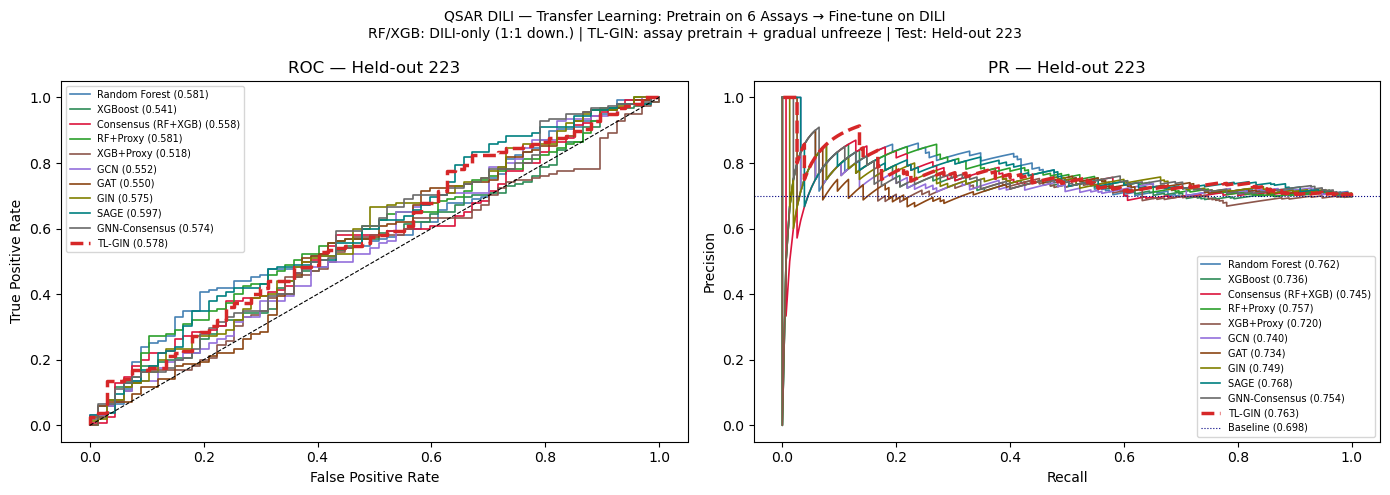

Saved → qsar_are_roc_pr.png


In [89]:
COLORS = {
    'Random Forest'      : 'steelblue',
    'XGBoost'            : 'seagreen',
    'Consensus (RF+XGB)' : 'crimson',
    'GCN'                : 'mediumpurple',
    'GAT'                : 'saddlebrown',
    'GIN'                : 'olive',
    'SAGE'               : 'teal',
    'GNN-Consensus'      : 'dimgray',
    'TL-GIN'             : '#d62728',
    'RF+Proxy'           : '#2ca02c',
    'XGB+Proxy'          : '#8c564b',
}

all_probs = {**all_test_probs, **gnn_probs}   # gnn_probs now includes TL-GIN
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for mname, prob in all_probs.items():
    lw = 2.5 if mname == 'TL-GIN' else 1.2
    ls = '--' if mname == 'TL-GIN' else '-'
    fpr, tpr, _ = roc_curve(y_te, prob)
    auc = roc_auc_score(y_te, prob)
    ax.plot(fpr, tpr, label=f'{mname} ({auc:.3f})', color=COLORS.get(mname, 'gray'), lw=lw, ls=ls)
ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
ax.set(title='ROC — Held-out 223', xlabel='False Positive Rate', ylabel='True Positive Rate')
ax.legend(fontsize=7)

ax = axes[1]
for mname, prob in all_probs.items():
    lw = 2.5 if mname == 'TL-GIN' else 1.2
    ls = '--' if mname == 'TL-GIN' else '-'
    prec, rec, _ = precision_recall_curve(y_te, prob)
    pr_auc = average_precision_score(y_te, prob)
    ax.plot(rec, prec, label=f'{mname} ({pr_auc:.3f})', color=COLORS.get(mname, 'gray'), lw=lw, ls=ls)
ax.axhline(y_te.mean(), color='navy', linestyle=':', lw=0.8, label=f'Baseline ({y_te.mean():.3f})')
ax.set(title='PR — Held-out 223', xlabel='Recall', ylabel='Precision')
ax.legend(fontsize=7)

plt.suptitle(
    'QSAR DILI — Transfer Learning: Pretrain on 6 Assays → Fine-tune on DILI\n'
    'RF/XGB: DILI-only (1:1 down.) | TL-GIN: assay pretrain + gradual unfreeze | Test: Held-out 223',
    fontsize=10
)
plt.tight_layout()
plt.savefig(f'{BASE}/combined/qsar_are_roc_pr.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → qsar_are_roc_pr.png')

---
## Step 13 — Final Summary Table

In [90]:
rows = (
    [r for _, r in classical_results.values()]
    + list(gnn_results.values())
)
results_df = (
    pd.DataFrame(rows)[METRIC_COLS]
    .sort_values('ROC-AUC', ascending=False)
    .reset_index(drop=True)
)

print('=== Results on Held-out 223 Test Set ===')
print('RF/XGB : ECFP4, trained on proxy-12133 + NCV-888 (1:1 downsample, val-AUC HP search)')
print('Direct GNNs: graph features, DILI-only training (1:1 balanced)')
print('TL-GIN : pretrained on 6 assays → gradual-unfreeze fine-tuned on DILI')
print(results_df.to_string(index=False))

results_df.to_csv(f'{BASE}/combined/qsar_are_results.csv', index=False)
print('\nSaved → qsar_are_results.csv')

=== Results on Held-out 223 Test Set ===
RF/XGB : ECFP4, trained on proxy-12133 + NCV-888 (1:1 downsample, val-AUC HP search)
Direct GNNs: graph features, DILI-only training (1:1 balanced)
TL-GIN : pretrained on 6 assays → gradual-unfreeze fine-tuned on DILI
             Model  Sensitivity  Specificity  CCR  ROC-AUC  PR-AUC    MCC     F1
              SAGE         74.8         35.8 55.3   0.5975  0.7680 0.1085 0.7389
     Random Forest         61.3         41.8 51.5   0.5813  0.7622 0.0289 0.6574
          RF+Proxy         64.5         46.3 55.4   0.5806  0.7569 0.1016 0.6873
            TL-GIN         73.5         37.3 55.4   0.5782  0.7630 0.1091 0.7331
               GIN         59.4         53.7 56.5   0.5746  0.7490 0.1208 0.6619
     GNN-Consensus         63.2         47.8 55.5   0.5743  0.7544 0.1029 0.6806
Consensus (RF+XGB)         60.0         40.3 50.1   0.5582  0.7452 0.0028 0.6458
               GCN         65.2         43.3 54.2   0.5519  0.7403 0.0801 0.6871
            

---
## Step 15 — Graph Transformers: GraphGPS + Graphormer-lite

| Model | Key idea | Why better for molecules |
|-------|----------|--------------------------|
| **GraphGPS** ([Rampasek et al. 2022](https://github.com/rampasek/graphgps)) | Local MPNN (GINe) + global multi-head attention per layer | Local bond context + global structural awareness |
| **Graphormer-lite** ([Ying et al. 2021](https://github.com/microsoft/graphormer)) | Degree centrality encoding + global transformer attention | Every atom attends to every other atom; structural bias |

**GraphGPS**: PyG `GPSConv` (reference implementation). Local conv is `GINEConv` using 6-dim bond edge features.  
**Graphormer-lite**: `to_dense_batch` -> `nn.TransformerEncoder` globally over all atoms + degree encoding.  
Full Graphormer shortest-path spatial encoding is omitted (O(n2) per graph) — this is 'lite'.  
Both trained on same 1:1 balanced DILI splits and evaluated on held-out 222.

In [91]:
from torch_geometric.nn import GPSConv, GINEConv
from torch_geometric.utils import to_dense_batch, degree as pyg_degree

# ── Step 15: Graph Transformers
# GraphGPS (Rampasek et al. 2022): combines local MPNN + global self-attention
# Graphormer-lite  degree centrality + global transformer
#
#   - BatchNorm after each layer (stabilises training of deep nets)
#   - Residual connections inside GPS conv (prevents vanishing gradients)
#   - Dropout for regularisation (Ch.11)
#   - ReduceLROnPlateau + early stopping (Ch.11)
#   - pos_weight for class imbalance (Ch.3)
#   - FeatureNet proxy features injected after pooling (Seal et al. 2024)
#   - proxy_dim read from N_PROXY so no hardcoded numbers

class GraphGPS(nn.Module):
    """GraphGPS: local GINe MPNN + global multi-head self-attention per layer.
    Each layer: h = LayerNorm(MPNN(h) + Attn(h) + h)  [GPS formulation].
    proxy_dim proxy features concatenated after global mean pool.
    """
    def __init__(self, in_dim, hidden=128, n_layers=3, dropout=0.3,
                 heads=4, proxy_dim=0):
        super().__init__()
        self.proxy_dim  = proxy_dim
        self.input_proj = nn.Linear(in_dim, hidden)
        self.convs = nn.ModuleList([
            GPSConv(
                channels=hidden,
                conv=GINEConv(
                    nn.Sequential(
                        nn.Linear(hidden, hidden), nn.ReLU(),
                        nn.BatchNorm1d(hidden),
                        nn.Linear(hidden, hidden)
                    ),
                    edge_dim=6          # bond features: 4 bond types + conjugated + in_ring
                ),
                heads=heads,
                dropout=dropout,
                attn_type='multihead'  # standard scaled dot-product attention
            )
            for _ in range(n_layers)
        ])
        self.bns = nn.ModuleList([nn.BatchNorm1d(hidden) for _ in range(n_layers)])
        self.dropout = dropout
        # Head: hidden + proxy_dim → binary logit
        head_in = hidden + proxy_dim
        self.head = nn.Sequential(
            nn.Linear(head_in, hidden // 2), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden // 2, 1)
        )

    def forward(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch
        h = self.input_proj(x)
        for conv, bn in zip(self.convs, self.bns):
            h = bn(F.relu(conv(h, ei, batch, edge_attr=ea)))
            h = F.dropout(h, p=self.dropout, training=self.training)
        h_graph = global_mean_pool(h, batch)            # (B, hidden)
        # FeatureNet proxy injection (Seal et al. 2024)
        if self.proxy_dim > 0 and hasattr(data, 'proxy'):
            proxy   = data.proxy.view(h_graph.size(0), self.proxy_dim)
            h_graph = torch.cat([h_graph, proxy], dim=-1)
        return self.head(h_graph).squeeze(-1)


class GraphormerLite(nn.Module):
    """Graphormer-lite: degree centrality encoding + global Transformer.
    Ying et al. 2021: node degree encodes structural position information.
    Shortest-path encoding omitted (O(n²)) — this is the lite version.
    proxy_dim proxy features concatenated after global mean pool.
    """
    def __init__(self, in_dim, hidden=128, n_layers=3, dropout=0.3,
                 heads=4, max_degree=10, proxy_dim=0):
        super().__init__()
        self.max_degree     = max_degree
        self.proxy_dim      = proxy_dim
        self.input_proj     = nn.Linear(in_dim, hidden)
        # Centrality encoding: embed in-degree, add to node features
        self.degree_encoder = nn.Embedding(max_degree + 1, hidden)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=hidden,
            nhead=heads,
            dim_feedforward=hidden * 4,  # standard Transformer: 4× hidden
            dropout=dropout,
            batch_first=True,
            norm_first=True              # pre-LN (Wang et al. 2019): more stable
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)
        self.dropout = dropout
        head_in = hidden + proxy_dim
        self.head = nn.Sequential(
            nn.Linear(head_in, hidden // 2), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden // 2, 1)
        )

    def forward(self, data):
        x, ei, batch = data.x, data.edge_index, data.batch
        # Centrality encoding
        deg = pyg_degree(ei[0], x.size(0), dtype=torch.long).clamp(max=self.max_degree)
        h   = self.input_proj(x) + self.degree_encoder(deg)
        # Pad to dense batch for Transformer (molecules have variable #atoms)
        h_dense, mask = to_dense_batch(h, batch)        # (B, max_N, hidden)
        h_out  = self.transformer(h_dense, src_key_padding_mask=~mask)
        h_out  = h_out[mask]                            # back to sparse
        h_graph = global_mean_pool(h_out, batch)        # (B, hidden)
        # FeatureNet proxy injection
        if self.proxy_dim > 0 and hasattr(data, 'proxy'):
            proxy   = data.proxy.view(h_graph.size(0), self.proxy_dim)
            h_graph = torch.cat([h_graph, proxy], dim=-1)
        return self.head(h_graph).squeeze(-1)


print('GraphGPS and Graphormer-lite defined.')
print(f'  GraphGPS     : local GINe MPNN + global MHA per layer')
print(f'  Graphormer   : degree centrality + pre-LN Transformer')
print(f'  Proxy dim    : {N_PROXY}  (injected after global mean pool)')


GraphGPS and Graphormer-lite defined.
  GraphGPS     : local GINe MPNN + global MHA per layer
  Graphormer   : degree centrality + pre-LN Transformer
  Proxy dim    : 7  (injected after global mean pool)


In [92]:
# ── Step 15b: Graph Transformer Training ───────────────────────────────────
# Uses same loaders, criterion and EPOCHS/PATIENCE as direct GNNs (Step 10)
# so the comparison is fair (identical data splits and stopping criteria).
# Géron Ch.2: all models evaluated on the SAME held-out test set.

GT_CONFIGS = {
    'GraphGPS'  : {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'heads': 4, 'lr': 1e-3},
    'Graphormer': {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'heads': 4, 'lr': 1e-3},
}

gt_results = {}
gt_probs   = {}

# y_te needed for evaluate() — same as splits['y_test']
y_te = splits['y_test']

print('=== Step 15: Graph Transformer Training ===')
print(f'  Loaders  : {len(tr_loader.dataset):,} train | {len(va_loader.dataset):,} val | {len(te_loader.dataset):,} test')
print(f'  Epochs   : {EPOCHS}  Patience: {PATIENCE}  Batch: {BATCH}')
print(f'  Proxy dim: {N_PROXY}  Device: {DEVICE}')
print()

for arch, cfg in GT_CONFIGS.items():
    lr  = cfg['lr']
    kw  = {k: v for k, v in cfg.items() if k != 'lr'}

    model = (
        GraphGPS(ATOM_DIM, **kw, proxy_dim=N_PROXY)
        if arch == 'GraphGPS'
        else GraphormerLite(ATOM_DIM, **kw, proxy_dim=N_PROXY)
    ).to(DEVICE)

    opt   = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode='max', patience=8, factor=0.5, min_lr=1e-5)
    best_val, best_state = 0.0, None
    no_imp = 0

    print(f'  Training {arch} ...')
    for ep in range(EPOCHS):
        train_epoch(model, tr_loader, opt, crit, DEVICE)
        p_va, y_va_g = get_probs(model, va_loader, DEVICE)
        if len(np.unique(y_va_g)) < 2:
            continue
        auc_va = roc_auc_score(y_va_g, p_va)
        sched.step(auc_va)

        if auc_va > best_val:
            best_val  = auc_va
            best_state = copy.deepcopy(model.state_dict())
            no_imp    = 0
        else:
            no_imp += 1

        if (ep + 1) % 10 == 0:
            print(f'    Epoch {ep+1:>3}  val_AUC={auc_va:.4f}  best={best_val:.4f}')
        if no_imp >= PATIENCE:
            print(f'    Early stop at epoch {ep+1}')
            break

    # Load best weights (Géron Ch.11: restore best checkpoint)
    model.load_state_dict(best_state)
    p_te, _ = get_probs(model, te_loader, DEVICE)
    r = evaluate(y_te, p_te, arch)
    gt_results[arch] = r
    gt_probs[arch]   = p_te
    print(f'  {arch:<14}  val={best_val:.4f}  test AUC={r["ROC-AUC"]}  CCR={r["CCR"]}%  MCC={r["MCC"]}')
    print()

# Merge into global dicts for final table and plots
gnn_results.update(gt_results)
gnn_probs.update(gt_probs)
print('Graph Transformer results merged into gnn_results.')


=== Step 15: Graph Transformer Training ===
  Loaders  : 5,766 train | 874 val | 222 test
  Epochs   : 60  Patience: 15  Batch: 64
  Proxy dim: 7  Device: cpu

  Training GraphGPS ...
    Epoch  10  val_AUC=0.6078  best=0.6201
    Early stop at epoch 18
  GraphGPS        val=0.6201  test AUC=0.583  CCR=54.4%  MCC=0.0832

  Training Graphormer ...
    Epoch  10  val_AUC=0.5746  best=0.5962
    Epoch  20  val_AUC=0.5962  best=0.6171
    Epoch  30  val_AUC=0.5925  best=0.6231
    Early stop at epoch 39
  Graphormer      val=0.6231  test AUC=0.6031  CCR=57.5%  MCC=0.1461

Graph Transformer results merged into gnn_results.


=== Final Results — All Models on Held-out 223 ===
             Model  Sensitivity  Specificity  CCR  ROC-AUC  PR-AUC    MCC     F1
        Graphormer         70.3         44.8 57.5   0.6031  0.7668 0.1461 0.7243
              SAGE         74.8         35.8 55.3   0.5975  0.7680 0.1085 0.7389
          GraphGPS         43.2         65.7 54.4   0.5830  0.7545 0.0832 0.5469
     Random Forest         61.3         41.8 51.5   0.5813  0.7622 0.0289 0.6574
          RF+Proxy         64.5         46.3 55.4   0.5806  0.7569 0.1016 0.6873
            TL-GIN         73.5         37.3 55.4   0.5782  0.7630 0.1091 0.7331
               GIN         59.4         53.7 56.5   0.5746  0.7490 0.1208 0.6619
     GNN-Consensus         63.2         47.8 55.5   0.5743  0.7544 0.1029 0.6806
Consensus (RF+XGB)         60.0         40.3 50.1   0.5582  0.7452 0.0028 0.6458
               GCN         65.2         43.3 54.2   0.5519  0.7403 0.0801 0.6871
               GAT         53.5         58.2 55.9   0.5503

Saved -> qsar_final_bar.png


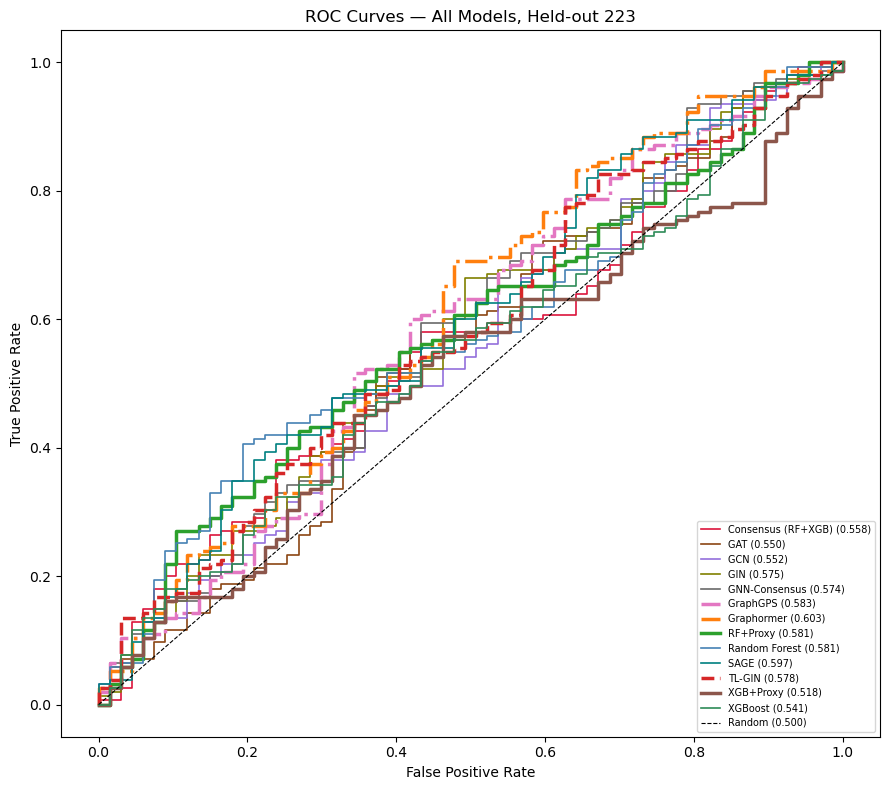

Saved -> qsar_final_roc.png


In [93]:
# ── Step 15c: Final Comparison Table + Charts (all models) ─────────────────
# Géron Ch.2: all models ranked on the SAME held-out test set (223 compounds)

GT_NAMES = set(gt_results.keys())

# Add GT colors to COLORS dict
COLORS.update({
    'GraphGPS'  : '#e377c2',   # pink
    'Graphormer': '#ff7f0e',   # orange
})

all_rows = (
    [r for _, r in classical_results.values()]
    + list(gnn_results.values())   # includes direct GNNs + TL-GIN + GT models
)
final_df = (
    pd.DataFrame(all_rows)[METRIC_COLS]
    .sort_values('ROC-AUC', ascending=False)
    .reset_index(drop=True)
)
print('=== Final Results — All Models on Held-out 223 ===')
print(final_df.to_string(index=False))
final_df.to_csv(f'{BASE}/combined/qsar_final_results.csv', index=False)
print('\nSaved -> qsar_final_results.csv')

# ── Bar chart ───────────────────────────────────────────────────────────────
from matplotlib.patches import Patch

def bar_color_full(name):
    if name == 'TL-GIN':                        return '#d62728'  # red
    if name in GT_NAMES:                        return '#ff7f0e'  # orange
    if name in ('RF+Proxy', 'XGB+Proxy'):       return '#2ca02c'  # green
    if name in gnn_results:                     return '#9467bd'  # purple
    return '#1f77b4'                                              # blue (classical)

model_names = final_df['Model'].tolist()
colors_bar  = [bar_color_full(m) for m in model_names]

fig, axes = plt.subplots(1, 4, figsize=(24, 6))
for ax, metric in zip(axes, ['ROC-AUC', 'PR-AUC', 'CCR', 'MCC']):
    vals = final_df[metric].values
    bars = ax.bar(model_names, vals, color=colors_bar, edgecolor='white', linewidth=0.5)
    ax.set_title(metric, fontsize=13, fontweight='bold')
    ax.set_ylim(0, 1.0)
    ax.set_xticklabels(model_names, rotation=45, ha='right', fontsize=8)
    ax.axhline(0.5, color='gray', lw=0.8, ls='--', label='random (ROC)')
    if metric == 'PR-AUC':
        # PR-AUC random baseline = positive prevalence in test set
        pos_prev = splits['y_test'].mean()
        ax.axhline(pos_prev, color='orange', lw=0.8, ls=':', label=f'random PR ({pos_prev:.2f})')
        ax.legend(fontsize=7)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{v:.3f}', ha='center', va='bottom', fontsize=7)

axes[0].legend(handles=[
    Patch(facecolor='#1f77b4', label='Classical ML (ECFP4)'),
    Patch(facecolor='#2ca02c', label='Classical ML + Proxy'),
    Patch(facecolor='#9467bd', label='Direct GNN'),
    Patch(facecolor='#d62728', label='TL-GIN (transfer learning)'),
    Patch(facecolor='#ff7f0e', label='Graph Transformer'),
], fontsize=8, loc='lower right')

plt.suptitle(
    'QSAR DILI — All Models on Held-out 223\n'
    'Training: proxy-12133 | Val: NCV-888 | Features: ECFP4 + 7 proxy probs (FeatureNet)',
    fontsize=11)
plt.tight_layout()
plt.savefig(f'{BASE}/combined/qsar_final_bar.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved -> qsar_final_bar.png')

# ── ROC curves (all models) ─────────────────────────────────────────────────
all_probs_full = {**all_test_probs, **gnn_probs}
fig, ax = plt.subplots(figsize=(9, 8))
for mname, prob in sorted(all_probs_full.items()):
    fpr, tpr, _ = roc_curve(y_te, prob)
    auc_val     = roc_auc_score(y_te, prob)
    lw = 2.5 if mname in ('TL-GIN', 'GraphGPS', 'Graphormer', 'RF+Proxy', 'XGB+Proxy') else 1.2
    ls = '--' if mname == 'TL-GIN' else ('-.' if mname in GT_NAMES else '-')
    ax.plot(fpr, tpr, label=f'{mname} ({auc_val:.3f})',
            color=COLORS.get(mname, 'gray'), lw=lw, ls=ls)
ax.plot([0,1],[0,1], 'k--', lw=0.8, label='Random (0.500)')
ax.set(title='ROC Curves — All Models, Held-out 223',
       xlabel='False Positive Rate', ylabel='True Positive Rate')
ax.legend(fontsize=7, loc='lower right')
plt.tight_layout()
plt.savefig(f'{BASE}/combined/qsar_final_roc.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved -> qsar_final_roc.png')
